# 07 – Model training and comparison

All candidates are compared with nested cross-validation on the training set; the test set is not used.

- **Outer loop**: 5 folds, stratified by failure mode. Each candidate is scored on the held-out fold with PR-AUC (average precision).
- **Inner loop**: within the four training folds, a 3-fold grid search selects the hyperparameters, including whether failures receive extra class weight.

Tuning only on the inner folds keeps the outer scores free of tuning bias, so the candidates are compared fairly. The same outer folds are used for every candidate, which allows the fold-by-fold comparison required by H2. The search grids are defined in `src/models.py`.

In [1]:
import json
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_validate

from config import (CV_FOLDS, FIG_DIR, H2_MIN_FOLDS, H2_MIN_GAIN, H3_MIN_GAIN, PRIMARY_METRIC,
                    RESULTS_DIR, SEED, SELECTION_TOLERANCE)
from data import failure_stratum, load_train_test
from features import build_features
from models import CANDIDATES, complexity, make_pipeline, param_grid

train, _ = load_train_test()
X_train, y_train = build_features(train)

outer_folds = list(StratifiedKFold(CV_FOLDS, shuffle=True, random_state=SEED).split(X_train, failure_stratum(train)))
inner_cv = StratifiedKFold(3, shuffle=True, random_state=SEED)


def make_search(model, feature_set, cv):
    grid = param_grid(model)
    if not grid:
        return make_pipeline(model, feature_set)
    return GridSearchCV(make_pipeline(model, feature_set), grid, scoring=PRIMARY_METRIC, cv=cv, n_jobs=-1)

## 1. Nested cross-validation

Runtime is a few minutes, mostly for the random forest.

In [2]:
fold_scores, fold_params = [], []
for model, feature_set in CANDIDATES:
    start = time.time()
    result = cross_validate(make_search(model, feature_set, inner_cv), X_train, y_train, cv=outer_folds,
                            scoring=PRIMARY_METRIC, return_estimator=True)
    for fold, (score, fitted) in enumerate(zip(result["test_score"], result["estimator"]), start=1):
        params = fitted.best_params_ if hasattr(fitted, "best_params_") else {}
        fold_scores.append({"model": model, "features": feature_set, "fold": fold, "pr_auc": score})
        fold_params.append({"model": model, "features": feature_set, "fold": fold,
                            **{name.removeprefix("model__"): str(value) for name, value in params.items()}})
    print(f"{model:20s} {feature_set:8s} mean PR-AUC {result['test_score'].mean():.3f}  ({time.time() - start:.0f} s)")

fold_scores = pd.DataFrame(fold_scores)
fold_params = pd.DataFrame(fold_params)
fold_scores.to_csv(RESULTS_DIR / "07_cv_fold_scores.csv", index=False)
fold_params.to_csv(RESULTS_DIR / "07_cv_fold_params.csv", index=False)

dummy                raw      mean PR-AUC 0.033  (0 s)
logistic_regression  raw      mean PR-AUC 0.460  (15 s)
logistic_regression  physics  mean PR-AUC 0.488  (2 s)
decision_tree        raw      mean PR-AUC 0.559  (3 s)
decision_tree        physics  mean PR-AUC 0.886  (3 s)
random_forest        raw      mean PR-AUC 0.764  (44 s)
random_forest        physics  mean PR-AUC 0.909  (57 s)


In [3]:
summary = (fold_scores.groupby(["model", "features"])["pr_auc"]
           .agg(["mean", "std", "min", "max"])
           .sort_values("mean", ascending=False))
summary.to_csv(RESULTS_DIR / "07_cv_summary.csv")
summary.round(3)

mean    std    min    max
model               features                            
random_forest       physics   0.909  0.014  0.888  0.923
decision_tree       physics   0.886  0.010  0.874  0.899
random_forest       raw       0.764  0.083  0.668  0.848
decision_tree       raw       0.559  0.069  0.471  0.652
logistic_regression physics   0.488  0.042  0.426  0.524
                    raw       0.460  0.039  0.410  0.514
dummy               raw       0.033  0.000  0.033  0.034

Hyperparameters chosen by the inner search in each outer fold. Stable choices across folds indicate a robust setting. `None` means no class weighting (class_weight) or unlimited depth (random forest max_depth).

In [4]:
for model in ["logistic_regression", "decision_tree", "random_forest"]:
    display(fold_params[fold_params["model"] == model].dropna(axis=1, how="all").set_index(["model", "features", "fold"]))

C class_weight
model               features fold                
logistic_regression raw      1     1         None
                             2     1         None
                             3     1         None
                             4     1         None
                             5     1         None
                    physics  1     1         None
                             2     1         None
                             3     1         None
                             4     1         None
                             5     1         None

class_weight max_depth min_samples_leaf
model         features fold                                        
decision_tree raw      1            None         5               10
                       2            None         5               10
                       3            None         5                1
                       4            None         5               10
                       5            None         5               10
              physics  1            None         5               10
                       2            None         5               10
                       3            None         5               10
                       4            None         5               10
                       5            None         5               10

class_weight max_depth min_samples_leaf
model         features fold                                        
random_forest raw      1            None      None                1
                       2            None      None                1
                       3            None      None                1
                       4            None      None                1
                       5            None      None                1
              physics  1            None      None                1
                       2            None         8                1
                       3            None         8                1
                       4            None         8                1
                       5            None         8                1

The decision tree always selects the largest allowed depth (5). Deeper trees might score higher, but the depth is capped on purpose so that the tree stays readable; the random forest covers the high-capacity case.

## 2. Comparison figure

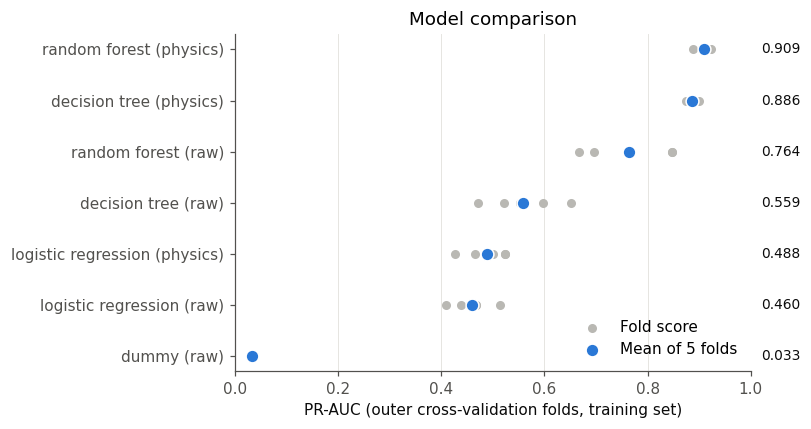

In [5]:
INK, MUTED, GRID, GRAY, BLUE = "#0b0b0b", "#52514e", "#e4e3df", "#b9b8b3", "#2a78d6"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight", "font.size": 10,
    "axes.edgecolor": MUTED, "axes.labelcolor": INK, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
    "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True, "legend.frameon": False,
})

order = summary.sort_values("mean").index
labels = [f"{model.replace('_', ' ')} ({features})" for model, features in order]
fig, ax = plt.subplots(figsize=(7.5, 4))
indexed = fold_scores.set_index(["model", "features"]).sort_index()
for row, key in enumerate(order):
    scores = indexed.loc[key, "pr_auc"]
    ax.scatter(scores, [row] * len(scores), s=24, color=GRAY, zorder=2, label="Fold score" if row == 0 else None)
    ax.scatter(scores.mean(), row, s=70, color=BLUE, edgecolor="white", linewidth=1, zorder=3,
               label="Mean of 5 folds" if row == 0 else None)
    ax.text(1.02, row, f"{scores.mean():.3f}", va="center", color=INK, fontsize=9)
ax.set_yticks(range(len(order)), labels)
ax.set_xlim(0, 1)
ax.set_xlabel("PR-AUC (outer cross-validation folds, training set)")
ax.set_title("Model comparison")
ax.grid(axis="y", visible=False)
ax.legend(loc="lower right")
fig.tight_layout()
fig.savefig(FIG_DIR / "07_cv_comparison.png")

## 3. Hypotheses evaluated on cross-validation (H2, H3)

In [6]:
by_fold = fold_scores.pivot_table(index="fold", columns=["model", "features"], values="pr_auc")

lr_gain = by_fold[("logistic_regression", "physics")] - by_fold[("logistic_regression", "raw")]
h2 = {
    "mean gain": lr_gain.mean(),
    "folds with a gain": int((lr_gain > 0).sum()),
    "accepted": bool(lr_gain.mean() >= H2_MIN_GAIN and (lr_gain > 0).sum() >= H2_MIN_FOLDS),
}

best_rf = summary.loc["random_forest", "mean"].max()
best_lr = summary.loc["logistic_regression", "mean"].max()
h3 = {"best random forest": best_rf, "best logistic regression": best_lr, "difference": best_rf - best_lr,
      "accepted": bool(best_rf - best_lr >= H3_MIN_GAIN)}

print(f"H2: logistic regression gain per fold: {lr_gain.round(3).tolist()}")
pd.DataFrame({"H2": pd.Series(h2), "H3": pd.Series(h3)})

H2: logistic regression gain per fold: [0.027, 0.032, 0.01, 0.017, 0.055]


,H2,H3
accepted,False,True
best logistic regression,NaN,0.488089
best random forest,NaN,0.908766
difference,NaN,0.420677
folds with a gain,5,NaN
mean gain,0.028319,NaN


In [7]:
tree_gain = pd.DataFrame({
    model: by_fold[(model, "physics")] - by_fold[(model, "raw")]
    for model in ["decision_tree", "random_forest"]
})
tree_gain.agg(["mean", "min", "max"]).round(3)

,decision_tree,random_forest
mean,0.327,0.144
min,0.222,0.074
max,0.423,0.220


The effect of the physics features on the tree models is reported as an observation (not a hypothesis).

## 4. Model selection

The candidate with the highest mean PR-AUC is selected; any candidate within the tolerance of the best is preferred if it is simpler (model complexity first, then fewer features).

In [8]:
best_score = summary["mean"].max()
contenders = summary[summary["mean"] >= best_score - SELECTION_TOLERANCE].copy()
contenders["complexity"] = [complexity(model, features) for model, features in contenders.index]
selected_model, selected_features = contenders.sort_values(["complexity", "mean"], ascending=[True, False]).index[0]

print(f"Best mean PR-AUC: {best_score:.3f}")
print(f"Candidates within {SELECTION_TOLERANCE}: {list(contenders.index)}")
print(f"Selected: {selected_model} with {selected_features} features")

Best mean PR-AUC: 0.909
Candidates within 0.01: [('random_forest', 'physics')]
Selected: random_forest with physics features


The final hyperparameters of the selected candidate are chosen with a grid search over the same five folds on the full training set.

In [9]:
final_search = make_search(selected_model, selected_features, outer_folds)
final_search.fit(X_train, y_train)
best_params = getattr(final_search, "best_params_", {})
final_params = {name.removeprefix("model__"): value for name, value in best_params.items()}

selection = {
    "model": selected_model,
    "features": selected_features,
    "params": final_params,
    "cv_pr_auc_mean": float(summary.loc[(selected_model, selected_features), "mean"]),
    "cv_pr_auc_std": float(summary.loc[(selected_model, selected_features), "std"]),
}
with open(RESULTS_DIR / "07_selected_model.json", "w") as f:
    json.dump(selection, f, indent=2)
selection

{'model': 'random_forest',
 'features': 'physics',
 'params': {'class_weight': None, 'max_depth': None, 'min_samples_leaf': 5},
 'cv_pr_auc_mean': 0.9087664064765887,
 'cv_pr_auc_std': 0.014466876808974995}